In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

old_data = gpd.read_parquet("../../data/input_files/uk_foursquare_datefields_admin_categories.parquet")
new_data = gpd.read_parquet("../../data/input_files/uk_foursquare_cc_admin.parquet")


#644034b95e434270126654b1 in new_data
new_data_test = new_data[new_data['fsq_place_id'] == '644034b95e434270126654b1']
#new data filter anything that has a date_closed (not null) or no fsq_category_id
old_data_test = old_data[old_data['fsq_place_id'] == '9514bc258bd145613838867b']


In [2]:
#drop any with no fsq_category_id
new_data = new_data[new_data['fsq_category_id'].notna()]

In [3]:
#count the number of unique  fsq_place_id in each dataset
old_unique = old_data['fsq_place_id'].nunique()
new_unique = new_data['fsq_place_id'].nunique()
print(f"Old data unique fsq_place_id count: {old_unique}")
print(f"New data unique fsq_place_id count: {new_unique}")

Old data unique fsq_place_id count: 3812934
New data unique fsq_place_id count: 3854044


In [4]:
#convert string to datetime
old_data['date_refreshed'] = gpd.pd.to_datetime(old_data['date_refreshed'])
new_data['date_refreshed'] = gpd.pd.to_datetime(new_data['date_refreshed'])
old_data['date_created'] = gpd.pd.to_datetime(old_data['date_created'])
new_data['date_created'] = gpd.pd.to_datetime(new_data['date_created'])
#get min date_refreshed
min_date = old_data['date_refreshed'].min()
min_date

Timestamp('2012-06-06 00:00:00')

/tmp/ipykernel_146520/3289724618.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  bins = pd.date_range(start='2010-01-01', end='2025-12-31', freq='M')


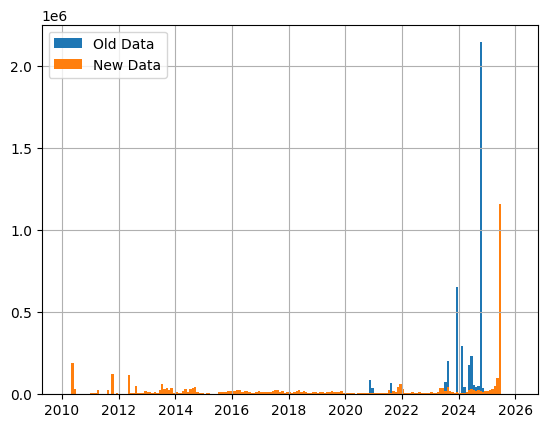

In [13]:
#bins between 2019 and 2021
bins = pd.date_range(start='2010-01-01', end='2025-12-31', freq='M')

old_data['date_refreshed'].hist(bins=bins)
new_data['date_refreshed'].hist(bins=bins)
plt.legend(['Old Data', 'New Data'])

New data Little Angels count: 144
Old data Little Angels count: 145


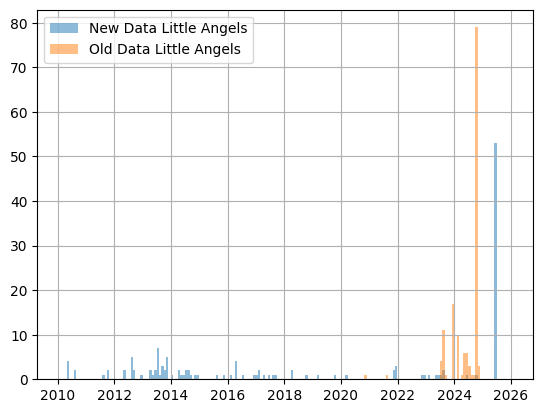

In [14]:
#count var in new and old data

name = "Little Angels"
new_data_somerfield = new_data[new_data['name'].str.contains(name, case=False, na=False)]
old_data_somerfield = old_data[old_data['name'].str.contains(name, case=False, na=False)]

print(f"New data {name} count: {new_data_somerfield.shape[0]}")
print(f"Old data {name} count: {old_data_somerfield.shape[0]}")

#plot the date_refreshed for somerfield in new and old data
new_data_somerfield['date_refreshed'].hist(bins=bins, alpha=0.5, label=f'New Data {name}')
old_data_somerfield['date_refreshed'].hist(bins=bins, alpha=0.5, label=f'Old Data {name}')
plt.legend()



In [16]:
#with locality Manchester
new_data_little_angels = new_data[new_data['name'].str.contains(name, case=False, na=False) & (new_data['locality'] == 'Manchester')]
old_data_little_angels = old_data[old_data['name'].str.contains(name, case=False, na=False) & (old_data['locality'] == 'Manchester')]


In [19]:
new_data_little_angels

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm
3701946,7a5abbbd2b2f45e5df94b070,Little Angels,53.442424,-2.279890,490 Wilbraham Rd,Manchester,Greater Manchester,M21 9AS,England,Manchester,...,None,None,None,None,None,None,None,None,None,None
3709919,3024cf6c6184440356f6fa40,Catherine's Little Angels,53.460585,-2.219936,88 Carmoor Rd,Manchester,Greater Manchester,M13 0FB,England,Manchester,...,None,None,None,None,None,None,None,None,None,None


In [ ]:
old_data_little_angels

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
747010,7a5abbbd2b2f45e5df94b070,Little Angels,53.442424,-2.279890,490 Wilbraham Rd,Manchester,Greater Manchester,M21 9AS,England,Manchester,...,Baby Store,None,None,None,None,None,None,None,None,2024-11-19
752354,3024cf6c6184440356f6fa40,Catherine's Little Angels,53.460585,-2.219936,88 Carmoor Rd,Manchester,Greater Manchester,M13 0FB,England,Manchester,...,Education,4f4533814b9074f6e4fb0107,Nursery School,None,None,None,None,None,None,2024-11-19


: 

In [30]:
#remove any not refreshed in 2025
new_data_somerfield = new_data_somerfield[new_data_somerfield['date_refreshed'] >= '2025-01-01']

In [33]:
new_data_somerfield

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm
37545,73a649f0f23345008891fb7f,Somerfield,53.558280,-0.030752,52 St Peters Ave,Cleethorpes,Lincolnshire,DN35 8HP,England,Cleethorpes,...,None,None,None,None,None,None,None,None,None,None
43870,52699177e4f745b9823c0fa2,Somerfield,53.564847,-0.084474,Osborne St Unit 1,Grimsby,Lincolnshire,DN31 1EY,England,Grimsby,...,None,None,None,None,None,None,None,None,None,None
61942,c9c0d7674e2140ca735953fc,Somerfield,52.669940,1.305663,100 The Paddocks,Norwich,Norfolk,NR6 7HS,England,Norwich,...,None,None,None,None,None,None,None,None,None,None
94608,09ab213f364b410b4830f281,Somerfield,52.665742,0.161260,Horse Fair,Wisbech,Cambridgeshire,PE13 1AR,England,Wisbech,...,None,None,None,None,None,None,None,None,None,None
96537,e7b4705d2eae48856b87786f,Somerfield,52.547068,0.087211,High St,March,Cambridgeshire,PE15 9LH,England,March,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4615489,4e4cd9ade9094c6ebe4d67d7,Somerfield,55.836961,-4.514357,High St,Johnstone,Renfrewshire,PA5 8QG,Scotland,Johnstone,...,S01012045,Johnstone North West - 03,None,None,None,None,None,None,None,None
4623826,2ea8b7bf884242dd252e8cf2,Somerfield,55.944348,-4.569796,5-17 College Way Unit R,Dumbarton,Dunbartonshire,G82 1LQ,Scotland,Dumbarton,...,S01013195,Dumbarton - 05,None,None,None,None,None,None,None,None
4624942,e17769c36a754a5be8dcbd1f,Somerfield,55.986436,-4.579683,2 Mitchell Way,Alexandria,Dunbartonshire,G83 0LW,Scotland,Arrochar,...,S01013223,Alexandria - 01,None,None,None,None,None,None,None,None
4629174,288db4cdce6e4c731c22493a,Somerfield,56.103438,-3.939647,Main St,Stirling,Stirlingshire,FK7 9AP,Scotland,Stirling,...,S01013059,King's Park and Torbrex - 01,None,None,None,None,None,None,None,None


In [ ]:
#join the two dataframes on fsq_place_id and keep the date columns for both
old_data = old_data[['fsq_place_id', 'date_refreshed', 'date_created','date_closed', 'name', 'fsq_category_ids',]]
new_data = new_data[['fsq_place_id', 'date_refreshed', 'date_created','date_closed', 'name', 'fsq_category_id',]]

#join
new_rows = new_data.merge(old_data, on='fsq_place_id', how='left', suffixes=('_new', '_old'))

#put pairs of columns next to each other
new_rows = new_rows[['fsq_place_id', 'name_new', 'name_old',
                     'date_refreshed_new', 'date_refreshed_old',
                     'date_created_new', 'date_created_old',
                     'date_closed_new', 'date_closed_old',
                     'fsq_category_id', 'fsq_category_ids']]

In [64]:
new_rows

,fsq_place_id,name_new,name_old,date_refreshed_new,date_refreshed_old,date_created_new,date_created_old,date_closed_new,date_closed_old,fsq_category_id,fsq_category_ids
0,5f04919b0654035c8098aa53,Horsey Beach,Horsey Beach,2024-12-03,2024-02-07,2020-07-07,2020-07-07,None,None,4bf58dd8d48988d1e2941735,4bf58dd8d48988d1e2941735
1,4c15006af1e0b713a1eb34bc,The Beach Café,The Beach Café,2024-08-17,2024-10-09,2010-06-13,2010-06-13,None,None,4bf58dd8d48988d1c7941735,4bf58dd8d48988d1c7941735
2,4ba5f36ef964a520ec2a39e3,Dunes Cafe,Dunes Cafe,2020-10-30,2024-02-07,2010-03-21,2010-03-21,None,None,4bf58dd8d48988d16d941735,4bf58dd8d48988d16d941735
3,61177e4454ff0843f151c7b3,Norfolk’s Edge,Norfolk’s Edge,2023-10-26,2024-02-07,2021-08-14,2021-08-14,None,None,4bf58dd8d48988d16d941735,4bf58dd8d48988d16d941735
4,4c2495de905a0f471eee5f60,Winterton On Sea Beach,Winterton On Sea Beach,2025-05-13,2024-02-07,2010-06-25,2010-06-25,None,None,4bf58dd8d48988d1e2941735,4bf58dd8d48988d1e2941735
...,...,...,...,...,...,...,...,...,...,...,...
2557540,536e4933498e867152e25320,Baltasound,Baltasound,2024-06-05,2020-12-08,2014-05-10,2014-05-10,None,None,50aa9e094b90af0d42d5de0d,50aa9e094b90af0d42d5de0d
2557541,4c2e6910ed37a593da8b6503,Baltasound Hotel,Baltasound Hotel,2023-08-23,2024-10-08,2010-07-02,2010-07-02,None,None,4bf58dd8d48988d1fa931735,4bf58dd8d48988d1fa931735
2557542,53cc4519498e1bf3446d0a79,Baltasound Harbour,Baltasound Harbour,2024-06-05,2024-10-09,2014-07-20,2014-07-20,None,None,4bf58dd8d48988d1e0941735,4bf58dd8d48988d1e0941735
2557543,64c52392f1a212750977a074,Norwick Beach,NaN,2023-07-29,NaT,2023-07-29,NaT,None,NaN,4bf58dd8d48988d1e2941735,NaN


In [6]:
#look for places Called Sommerfield
somerfield_places = new_rows[new_rows['name_new'].str.contains('Somerfield', case=False, na=False) |
                              new_rows['name_old'].str.contains('Somerfield', case=False, na=False)]

In [9]:
somerfield_places

,fsq_place_id,name_new,name_old,date_refreshed_new,date_refreshed_old,date_created_new,date_created_old,date_closed_new,date_closed_old,fsq_category_id,fsq_category_ids
4927,4cd6df0e122ba143b03c35a1,Somerfield,Somerfield,2016-06-20,2020-11-22,2010-11-07,2010-11-07,2016-06-20,2016-06-20,4bf58dd8d48988d113951735,4bf58dd8d48988d113951735
4952,4d345c0fc75a6ea805de1eae,Somerfield Hopton,NaN,2016-06-20,NaN,2011-01-17,NaN,2016-06-20,NaN,None,NaN
28538,4be071cbcb81c9b6b0e2658b,Somerfield,Somerfield,2015-10-13,2020-11-22,2010-05-04,2010-05-04,2015-10-13,2015-10-13,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
39844,a1b84d5e079c404391045eb9,Somerfield,Somerfield,2010-05-22,2024-10-08,2010-05-22,2010-05-22,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
48086,73a649f0f23345008891fb7f,Somerfield,Somerfield,2025-06-05,2024-06-15,2011-08-15,2011-08-15,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
...,...,...,...,...,...,...,...,...,...,...,...
5794005,180b303933e64b577e1fe728,Somerfield,Somerfield,2011-08-15,2024-10-09,2011-08-15,2011-08-15,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
5797870,2ea8b7bf884242dd252e8cf2,Somerfield,Somerfield,2025-06-05,2023-12-04,2011-10-30,2011-10-30,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
5799244,e17769c36a754a5be8dcbd1f,Somerfield,Somerfield,2025-06-05,2024-10-09,2011-08-15,2011-08-15,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735
5804554,288db4cdce6e4c731c22493a,Somerfield,Somerfield,2025-06-05,2023-12-04,2011-10-30,2011-10-30,None,None,4bf58dd8d48988d118951735,4bf58dd8d48988d118951735


In [4]:

new_data = new_data[(new_data['date_closed'].isnull()) & (new_data['fsq_category_id'].notnull()) 
]
old_data = old_data[(old_data['date_closed'].isnull()) & (old_data['fsq_category_ids'].notnull())
]

In [50]:
#remove from old_data anything that has a date_created after the date_refreshed
old_data = old_data[old_data['date_refreshed'] > old_data['date_created']]

In [55]:
new_data['date_refreshed'].min()

Timestamp('2020-01-02 00:00:00')

In [5]:
#count the number of unique  fsq_place_id in each dataset
old_unique = old_data['fsq_place_id'].nunique()
new_unique = new_data['fsq_place_id'].nunique()
print(f"Old data unique fsq_place_id count: {old_unique}")
print(f"New data unique fsq_place_id count: {new_unique}")

Old data unique fsq_place_id count: 3512863
New data unique fsq_place_id count: 3531793


In [5]:
#count number of ids in old data that are not in new data
old_ids = set(old_data['fsq_place_id'])
new_ids = set(new_data['fsq_place_id'])
missing_ids = old_ids - new_ids
print(f"Number of fsq_place_id in old data not in new data: {len(missing_ids)}")
#get df of old rows
old_rows = old_data[old_data['fsq_place_id'].isin(missing_ids)]

Number of fsq_place_id in old data not in new data: 9819


In [6]:
#and vice versa
missing_ids_new = new_ids - old_ids
print(f"Number of fsq_place_id in new data not in old data: {len(missing_ids_new)}")

Number of fsq_place_id in new data not in old data: 50929


In [7]:
#get a df of the new rows
new_rows = new_data[new_data['fsq_place_id'].isin(missing_ids_new)]

In [ ]:
#get ones with a date created since 2025
new_rows = new_rows[new_rows['date_created'] <= '2024-09-01']

In [11]:
#is Little Angels in new_rows?
new_rows[new_rows['name'] == 'Little Angels']

,fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,...,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm


In [10]:
new_rows[['name', 'fsq_place_id', 'date_created', 'date_refreshed', 'fsq_category_id','lat','lng']].head(10)

,name,fsq_place_id,date_created,date_refreshed,fsq_category_id,lat,lng
95,The Palace Casino,5c5e3fc1bd3245eaa492f1e9,2014-09-30,2014-09-30,4bf58dd8d48988d182941735,52.696107,1.700298
96,The Palace Casino,5c5e3fc1bd3245eaa492f1e9,2014-09-30,2014-09-30,4d4b7105d754a06374d81259,52.696107,1.700298
486,J B Roofing & Property Maintenance Services,71cdecfa863d4955c1b86843,2014-09-01,2014-09-01,63be6904847c3692a84b9b61,52.704490,1.586010
661,Heathland Group Limited,3fa39a7f43f742fe69c5e07e,2021-04-10,2021-04-10,5453de49498eade8af355881,52.688120,1.620759
662,Heathland Aquatic Engineering,c297c2f252fa41e7a760a80a,2021-04-10,2021-04-10,5453de49498eade8af355881,52.688120,1.620759
669,Heathland Pontoon Solutions Limited,8b4d6e32672842b84ab23d3f,2018-11-30,2018-11-30,4d4b7105d754a06375d81259,52.688956,1.623066
670,Heathland Fountains Limited,f4426dd0285c40a66f3486e4,2018-11-30,2018-11-30,63be6904847c3692a84b9b55,52.688956,1.623066
671,Heathland Fountains,a914765329a542bcd6113fbf,2021-04-10,2021-04-10,5453de49498eade8af355881,52.688956,1.623066
672,Heathland Decking Services Limited,bd22b721ed25417b6478a543,2018-11-30,2018-11-30,63be6904847c3692a84b9b50,52.688956,1.623066
673,Heathland Decking Services Limited,bd22b721ed25417b6478a543,2018-11-30,2018-11-30,63be6904847c3692a84b9b5b,52.688956,1.623066


In [19]:
new_rows["date_refreshed"].max(), new_rows["date_refreshed"].min()

('2025-06-08', '2009-09-02')

In [ ]:
#save to parquet
new_rows.to_parquet("../data/input_files/new_fsq_places_before_2025.parquet")


: 